In [2]:
!pip install statsmodels

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.4 MB 985.5 kB/s eta 0:00:11
   -- ------------------------------------- 0.8/11.4 MB 1.2 MB/s eta 0:00:09
   ---- ----------------------------------- 1.3/11.4 MB 1.6 MB/s eta 0:00:07
   ------ --------------------------------- 1.8/11.4 MB 1.7 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/11.4 MB 1.8 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/11.4 MB 1.8 MB/s eta 0:00:06
   ---------- ----------------------------- 2.9/11.4 MB 1.7 MB/s eta 0:00:06
   ----------- ---------------------------- 3.1/11.4 MB 1.7 MB/s eta 0:00:05
   ----------- ---------------------------- 3.4/11.4 MB 1.6 MB/s eta 0:00:05
   ----------- ----------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


         Date  Close   Volume
0  2022-01-03  98.23  4789676
1  2022-01-04  97.57  4572345
2  2022-01-05  95.65  2450357
3  2022-01-06  95.25  3107710
4  2022-01-07  94.48  1673013
<class 'pandas.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    750 non-null    str    
 1   Close   750 non-null    float64
 2   Volume  750 non-null    int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 25.0 KB
None
            Close        Volume
count  750.000000  7.500000e+02
mean   100.933027  3.070485e+06
std     14.664679  1.141996e+06
min     75.280000  1.000528e+06
25%     88.785000  2.096817e+06
50%     97.985000  3.080814e+06
75%    115.160000  4.068964e+06
max    126.620000  4.999842e+06


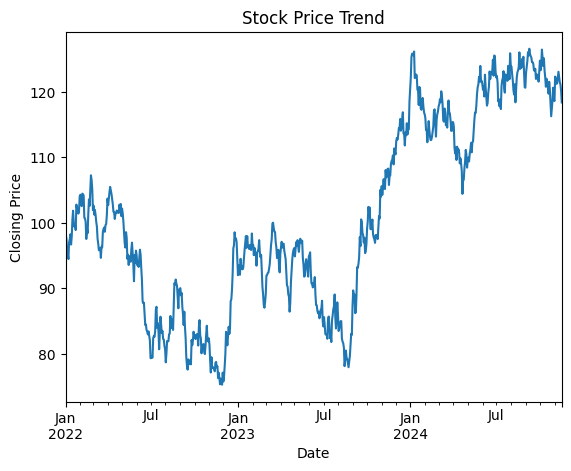

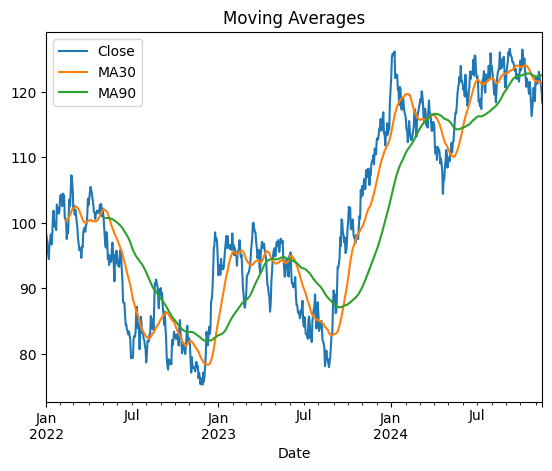

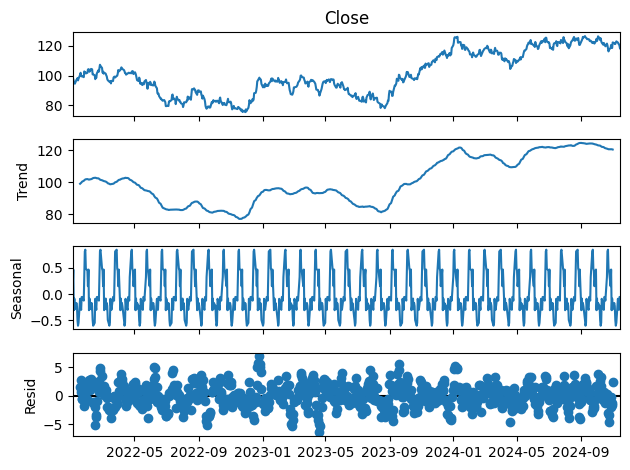

Correlation: -0.0019471899725632734


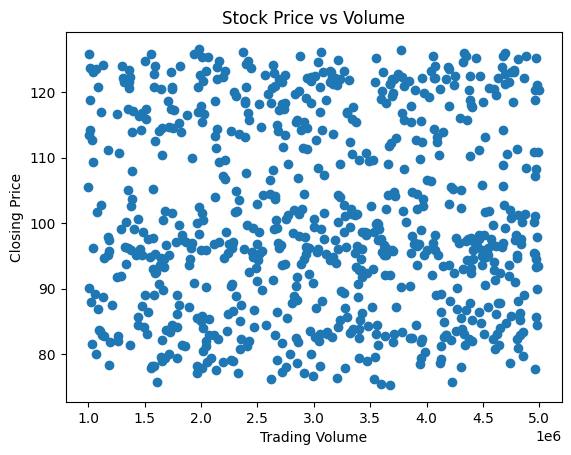

c:\Users\My PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\Users\My PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\Users\My PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)


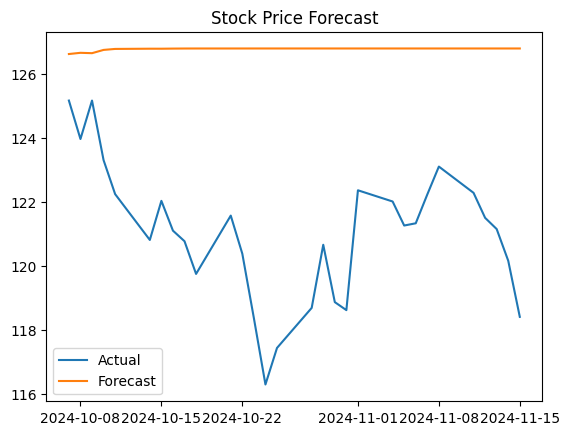

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Import dataset
df = pd.read_csv("Stock_Prices.csv")

# 2. Explore dataset
print(df.head())
print(df.info())
print(df.describe())

# 3. Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')
df = df.sort_index()

# 4. Plot historical stock prices
df['Close'].plot(title="Stock Price Trend")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

# 5. Calculate and plot moving averages
df['MA30'] = df['Close'].rolling(30).mean()
df['MA90'] = df['Close'].rolling(90).mean()

df[['Close', 'MA30', 'MA90']].plot(title="Moving Averages")
plt.show()

# 6. Seasonality analysis
result = seasonal_decompose(df['Close'], model='additive', period=21)
result.plot()
plt.show()

# 7. Correlation between stock price and volume
print("Correlation:", df['Close'].corr(df['Volume']))

plt.scatter(df['Volume'], df['Close'])
plt.xlabel("Trading Volume")
plt.ylabel("Closing Price")
plt.title("Stock Price vs Volume")
plt.show()

# 8. ARIMA forecasting
train = df['Close'][:-30]
test = df['Close'][-30:]

model = ARIMA(train, order=(5, 1, 0))
result = model.fit()

forecast = result.forecast(steps=30)

plt.plot(test.index, test, label="Actual")
plt.plot(test.index, forecast, label="Forecast")
plt.title("Stock Price Forecast")
plt.legend()
plt.show()